# EPA Air Quality: Data Preparation, Quality Review and Regression

This notebook takes a public US Environmental Protection Agency (EPA) air quality dataset of **218,635 records**, reviews its data quality, prepares it for modelling, and fits a linear regression model with explainability (SHAP).

**Context:** this began as my section of a group coursework project for CN6005 Artificial Intelligence at the University of East London (module mark 95%). I have since added the data quality review section and the limitations notes.

**Steps**
1. Extract: load the raw data
2. Data quality review
3. Transform: feature selection, missing values, encoding, skew handling
4. Model: train/test split, scaling, linear regression, baseline comparison
5. Explainability (SHAP)
6. Findings and limitations

**Data:** [EPA Air Quality Data on Kaggle](https://www.kaggle.com/datasets/thedevastator/epa-air-quality-data). Public, aggregated environmental measurements by US state and county. It contains no personal data.

**To run:** open in Google Colab and choose Runtime, then Run all.

## 0. Setup

In [1]:
# ==============================
# Import libraries
# ==============================

import pandas as pd
import numpy as np

# Visualisation libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Explainable AI
import shap

# Kaggle dataset downloader
import kagglehub


## 1. Extract: load the raw data

In [2]:
# ==============================
# Load EPA Air Quality dataset
# ==============================

path = kagglehub.dataset_download("thedevastator/epa-air-quality-data")
df = pd.read_csv(f"{path}/rows.csv")

# Preview dataset
df.head()

100%|██████████| 2.43M/2.43M [00:00<00:00, 3.97MB/s]

Extracting files...


,index,MeasureId,MeasureName,MeasureType,StratificationLevel,StateFips,StateName,CountyFips,CountyName,ReportYear,Value,Unit,UnitName,DataOrigin,MonitorOnly
0,0,83,Number of days with maximum 8-hour average ozo...,Counts,State x County,1,Alabama,1051,Elmore,1999,5.0,No Units,No Units,Monitor Only,1
1,1,83,Number of days with maximum 8-hour average ozo...,Counts,State x County,1,Alabama,1073,Jefferson,1999,39.0,No Units,No Units,Monitor Only,1
2,2,83,Number of days with maximum 8-hour average ozo...,Counts,State x County,1,Alabama,1079,Lawrence,1999,28.0,No Units,No Units,Monitor Only,1
3,3,83,Number of days with maximum 8-hour average ozo...,Counts,State x County,1,Alabama,1089,Madison,1999,31.0,No Units,No Units,Monitor Only,1
4,4,83,Number of days with maximum 8-hour average ozo...,Counts,State x County,1,Alabama,1097,Mobile,1999,32.0,No Units,No Units,Monitor Only,1


In [3]:
# Dataset structure
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 218635 entries, 0 to 218634
Data columns (total 15 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   index                218635 non-null  int64  
 1   MeasureId            218635 non-null  int64  
 2   MeasureName          218635 non-null  object 
 3   MeasureType          218635 non-null  object 
 4   StratificationLevel  218635 non-null  object 
 5   StateFips            218635 non-null  int64  
 6   StateName            218635 non-null  object 
 7   CountyFips           218635 non-null  int64  
 8   CountyName           218635 non-null  object 
 9   ReportYear           218635 non-null  int64  
 10  Value                218635 non-null  float64
 11  Unit                 218635 non-null  object 
 12  UnitName             218635 non-null  object 
 13  DataOrigin           218635 non-null  object 
 14  MonitorOnly          218635 non-null  int64  
dtypes: float64(1), in

In [4]:
# Summary statistics for numerical features
df.describe()


,index,MeasureId,StateFips,CountyFips,ReportYear,Value,MonitorOnly
count,218635.00000,218635.000000,218635.000000,218635.000000,218635.000000,2.186350e+05,218635.000000
mean,109317.00000,248.436979,30.228980,30328.039536,2005.997777,6.499649e+05,0.383950
std,63114.63239,86.333124,15.139346,15157.173159,3.432221,1.160826e+07,0.486347
min,0.00000,83.000000,1.000000,1001.000000,1999.000000,0.000000e+00,0.000000
25%,54658.50000,292.000000,18.000000,18146.000000,2003.000000,0.000000e+00,0.000000
50%,109317.00000,293.000000,29.000000,29189.000000,2006.000000,2.000000e+00,0.000000
75%,163975.50000,295.000000,45.000000,45021.000000,2009.000000,1.394105e+01,1.000000
max,218634.00000,296.000000,56.000000,56045.000000,2013.000000,1.084153e+09,1.000000


## 2. Data quality review

Before transforming anything, check the raw data: duplicates, missing values, data types, value ranges, and whether the `Value` column means the same thing on every row.

In [5]:
# Shape and data types
print("Rows, columns:", df.shape)
print()
print(df.dtypes)

Rows, columns: (218635, 15)

index                    int64
MeasureId                int64
MeasureName             object
MeasureType             object
StratificationLevel     object
StateFips                int64
StateName               object
CountyFips               int64
CountyName              object
ReportYear               int64
Value                  float64
Unit                    object
UnitName                object
DataOrigin              object
MonitorOnly              int64
dtype: object


In [6]:
# Missing values per column
df.isnull().sum()

,0
index,0
MeasureId,0
MeasureName,0
MeasureType,0
StratificationLevel,0
StateFips,0
StateName,0
CountyFips,0
CountyName,0
ReportYear,0


In [7]:
# Duplicate checks
# 'index' is a row counter, so exclude it when looking for duplicate records
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicate records (ignoring the 'index' column):",
      df.drop(columns=["index"]).duplicated().sum())

Fully duplicated rows: 0
Duplicate records (ignoring the 'index' column): 0


In [8]:
# Does 'Value' use the same unit on every row?
# Each MeasureName is a different measure, so list the units used by each one
units_per_measure = (
    df.groupby(["MeasureName", "Unit", "UnitName"])
      .size()
      .reset_index(name="rows")
      .sort_values("rows", ascending=False)
)
print("Distinct measures:", df["MeasureName"].nunique())
print("Distinct units:", df["Unit"].nunique())
units_per_measure

Distinct measures: 10
Distinct units: 3


,MeasureName,Unit,UnitName,rows
0,Annual average ambient concentrations of PM 2....,µg/m³,Micograms per cubic meter,34199
3,Number of days with maximum 8-hour average ozo...,No Units,No Units,34199
8,Percent of days with PM2.5 levels over the Nat...,%,Percent,34199
4,Number of person-days with PM2.5 over the Nati...,No Units,No Units,34199
6,Number of person-days with maximum 8-hour aver...,No Units,No Units,34199
5,Number of person-days with maximum 8-hour aver...,No Units,No Units,10341
2,Number of days with maximum 8-hour average ozo...,No Units,No Units,10341
7,Percent of days with PM2.5 levels over the Nat...,%,Percent,9268
9,Person-days with PM2.5 over the National Ambie...,No Units,No Units,9268
1,Annual average ambient concentrations of PM2.5...,µg/m³,Micograms per cubic meter,8422


In [9]:
# Value ranges per measure: look for negative or implausible values
print("Negative values:", (df["Value"] < 0).sum())
df.groupby("MeasureName")["Value"].describe()

Negative values: 0


,count,mean,std,min,25%,50%,75%,max
MeasureName,,,,,,,,
"Annual average ambient concentrations of PM 2.5 in micrograms per cubic meter, based on seasonal averages and daily measurement (monitor and modeled data)",34199.0,1.064170e+01,2.566426e+00,3.666171,8.746071,10.658495,1.242508e+01,3.034495e+01
Annual average ambient concentrations of PM2.5 in micrograms per cubic meter (based on seasonal averages and daily measurement),8422.0,1.122638e+01,3.225088e+00,1.635714,9.072201,11.055015,1.329585e+01,5.120158e+01
Number of days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard,10341.0,8.212262e+00,1.344608e+01,0.000000,0.000000,3.000000,1.100000e+01,1.460000e+02
Number of days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard (monitor and modeled data),34199.0,4.106787e+00,8.128565e+00,0.000000,0.000000,1.000000,5.000000e+00,1.440000e+02
Number of person-days with PM2.5 over the National Ambient Air Quality Standard (monitor and modeled data),34199.0,5.858132e+05,8.641115e+06,0.000000,0.000000,0.000000,6.758300e+04,8.182129e+08
Number of person-days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard,10341.0,5.001122e+06,3.447001e+07,0.000000,0.000000,382012.000000,1.957904e+06,1.084153e+09
Number of person-days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard (monitor and modeled data),34199.0,1.280902e+06,1.710800e+07,0.000000,0.000000,14807.000000,2.148010e+05,1.084153e+09
Percent of days with PM2.5 levels over the National Ambient Air Quality Standard (NAAQS),9268.0,1.270835e+00,2.467987e+00,0.000000,0.000000,0.000000,1.680672e+00,3.323263e+01
Percent of days with PM2.5 levels over the National Ambient Air Quality Standard (monitor and modeled data),34199.0,4.760193e-01,1.116116e+00,0.000000,0.000000,0.000000,5.479452e-01,3.205479e+01


In [10]:
# Coverage: years, states and counties
print("Years:", df["ReportYear"].min(), "to", df["ReportYear"].max())
print("States:", df["StateFips"].nunique())
print("Counties:", df["CountyFips"].nunique())

Years: 1999 to 2013
States: 51
Counties: 3120


### Data quality findings

*(Fill these in from the outputs above after running.)*

- **Missing values:** ...
- **Duplicates:** ...
- **Units:** the `Value` column combines several different measures (for example counts of days and concentrations), which use different units. This matters for the model below, which treats `Value` as one target.
- **Identifier columns:** `StateFips` and `CountyFips` are location codes, not quantities.
- **Coverage:** ...

## 3. Transform

In [11]:
# ==============================
# Step 3.1: Feature selection
# ==============================

df = df[
    [
        'Value',          # Target variable
        'MeasureName',    # Pollutant type
        'ReportYear',
        'StateFips',
        'CountyFips'
    ]
]

df.head()


,Value,MeasureName,ReportYear,StateFips,CountyFips
0,5.0,Number of days with maximum 8-hour average ozo...,1999,1,1051
1,39.0,Number of days with maximum 8-hour average ozo...,1999,1,1073
2,28.0,Number of days with maximum 8-hour average ozo...,1999,1,1079
3,31.0,Number of days with maximum 8-hour average ozo...,1999,1,1089
4,32.0,Number of days with maximum 8-hour average ozo...,1999,1,1097


In [12]:
# ==============================
# Step 3.2: Missing value handling
# ==============================

df.isnull().sum()


,0
Value,0
MeasureName,0
ReportYear,0
StateFips,0
CountyFips,0


In [13]:
# Remove rows with missing values
df = df.dropna()

print("Dataset shape after dropping missing values:", df.shape)


Dataset shape after dropping missing values: (218635, 5)


In [14]:
# ==============================
# Step 3.3: Encode categorical feature (one-hot)
# ==============================

df = pd.get_dummies(df, columns=['MeasureName'], drop_first=True)

df.head()


,Value,ReportYear,StateFips,CountyFips,MeasureName_Annual average ambient concentrations of PM2.5 in micrograms per cubic meter (based on seasonal averages and daily measurement),MeasureName_Number of days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard,MeasureName_Number of days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard (monitor and modeled data),MeasureName_Number of person-days with PM2.5 over the National Ambient Air Quality Standard (monitor and modeled data),MeasureName_Number of person-days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard,MeasureName_Number of person-days with maximum 8-hour average ozone concentration over the National Ambient Air Quality Standard (monitor and modeled data),MeasureName_Percent of days with PM2.5 levels over the National Ambient Air Quality Standard (NAAQS),MeasureName_Percent of days with PM2.5 levels over the National Ambient Air Quality Standard (monitor and modeled data),MeasureName_Person-days with PM2.5 over the National Ambient Air Quality Standard
0,5.0,1999,1,1051,False,True,False,False,False,False,False,False,False
1,39.0,1999,1,1073,False,True,False,False,False,False,False,False,False
2,28.0,1999,1,1079,False,True,False,False,False,False,False,False,False
3,31.0,1999,1,1089,False,True,False,False,False,False,False,False,False
4,32.0,1999,1,1097,False,True,False,False,False,False,False,False,False


### Skew in the target

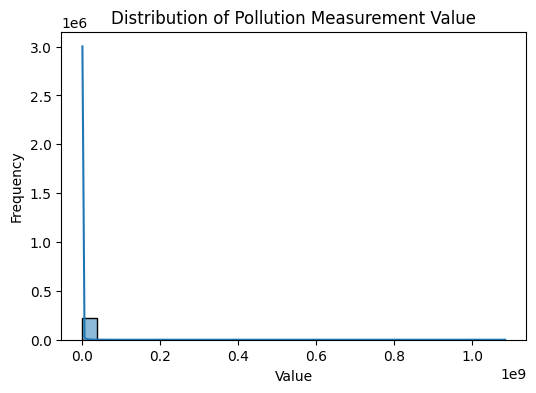

In [15]:
plt.figure(figsize=(6,4))
sns.histplot(df['Value'], bins=30, kde=True)
plt.title("Distribution of Pollution Measurement Value")
plt.xlabel("Value")
plt.ylabel("Frequency")
plt.show()


In [16]:
# ==============================
# Step 3.4: Log transformation
# ==============================

# Log-transform target to handle skewness and extreme outliers
df['Value_log'] = np.log1p(df['Value'])  # log(1 + x) avoids log(0)


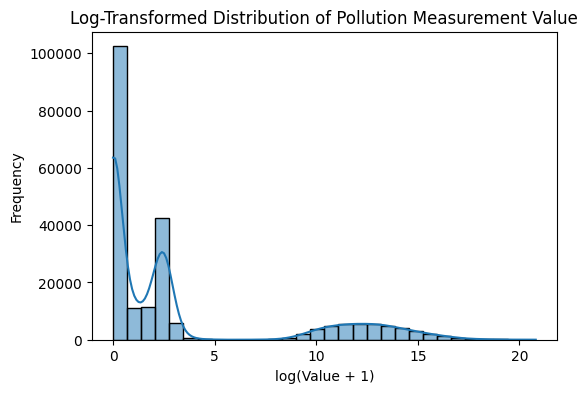

In [17]:
# Visualise transformed distribution
plt.figure(figsize=(6,4))
sns.histplot(df['Value_log'], bins=30, kde=True)
plt.title("Log-Transformed Distribution of Pollution Measurement Value")
plt.xlabel("log(Value + 1)")
plt.ylabel("Frequency")
plt.show()


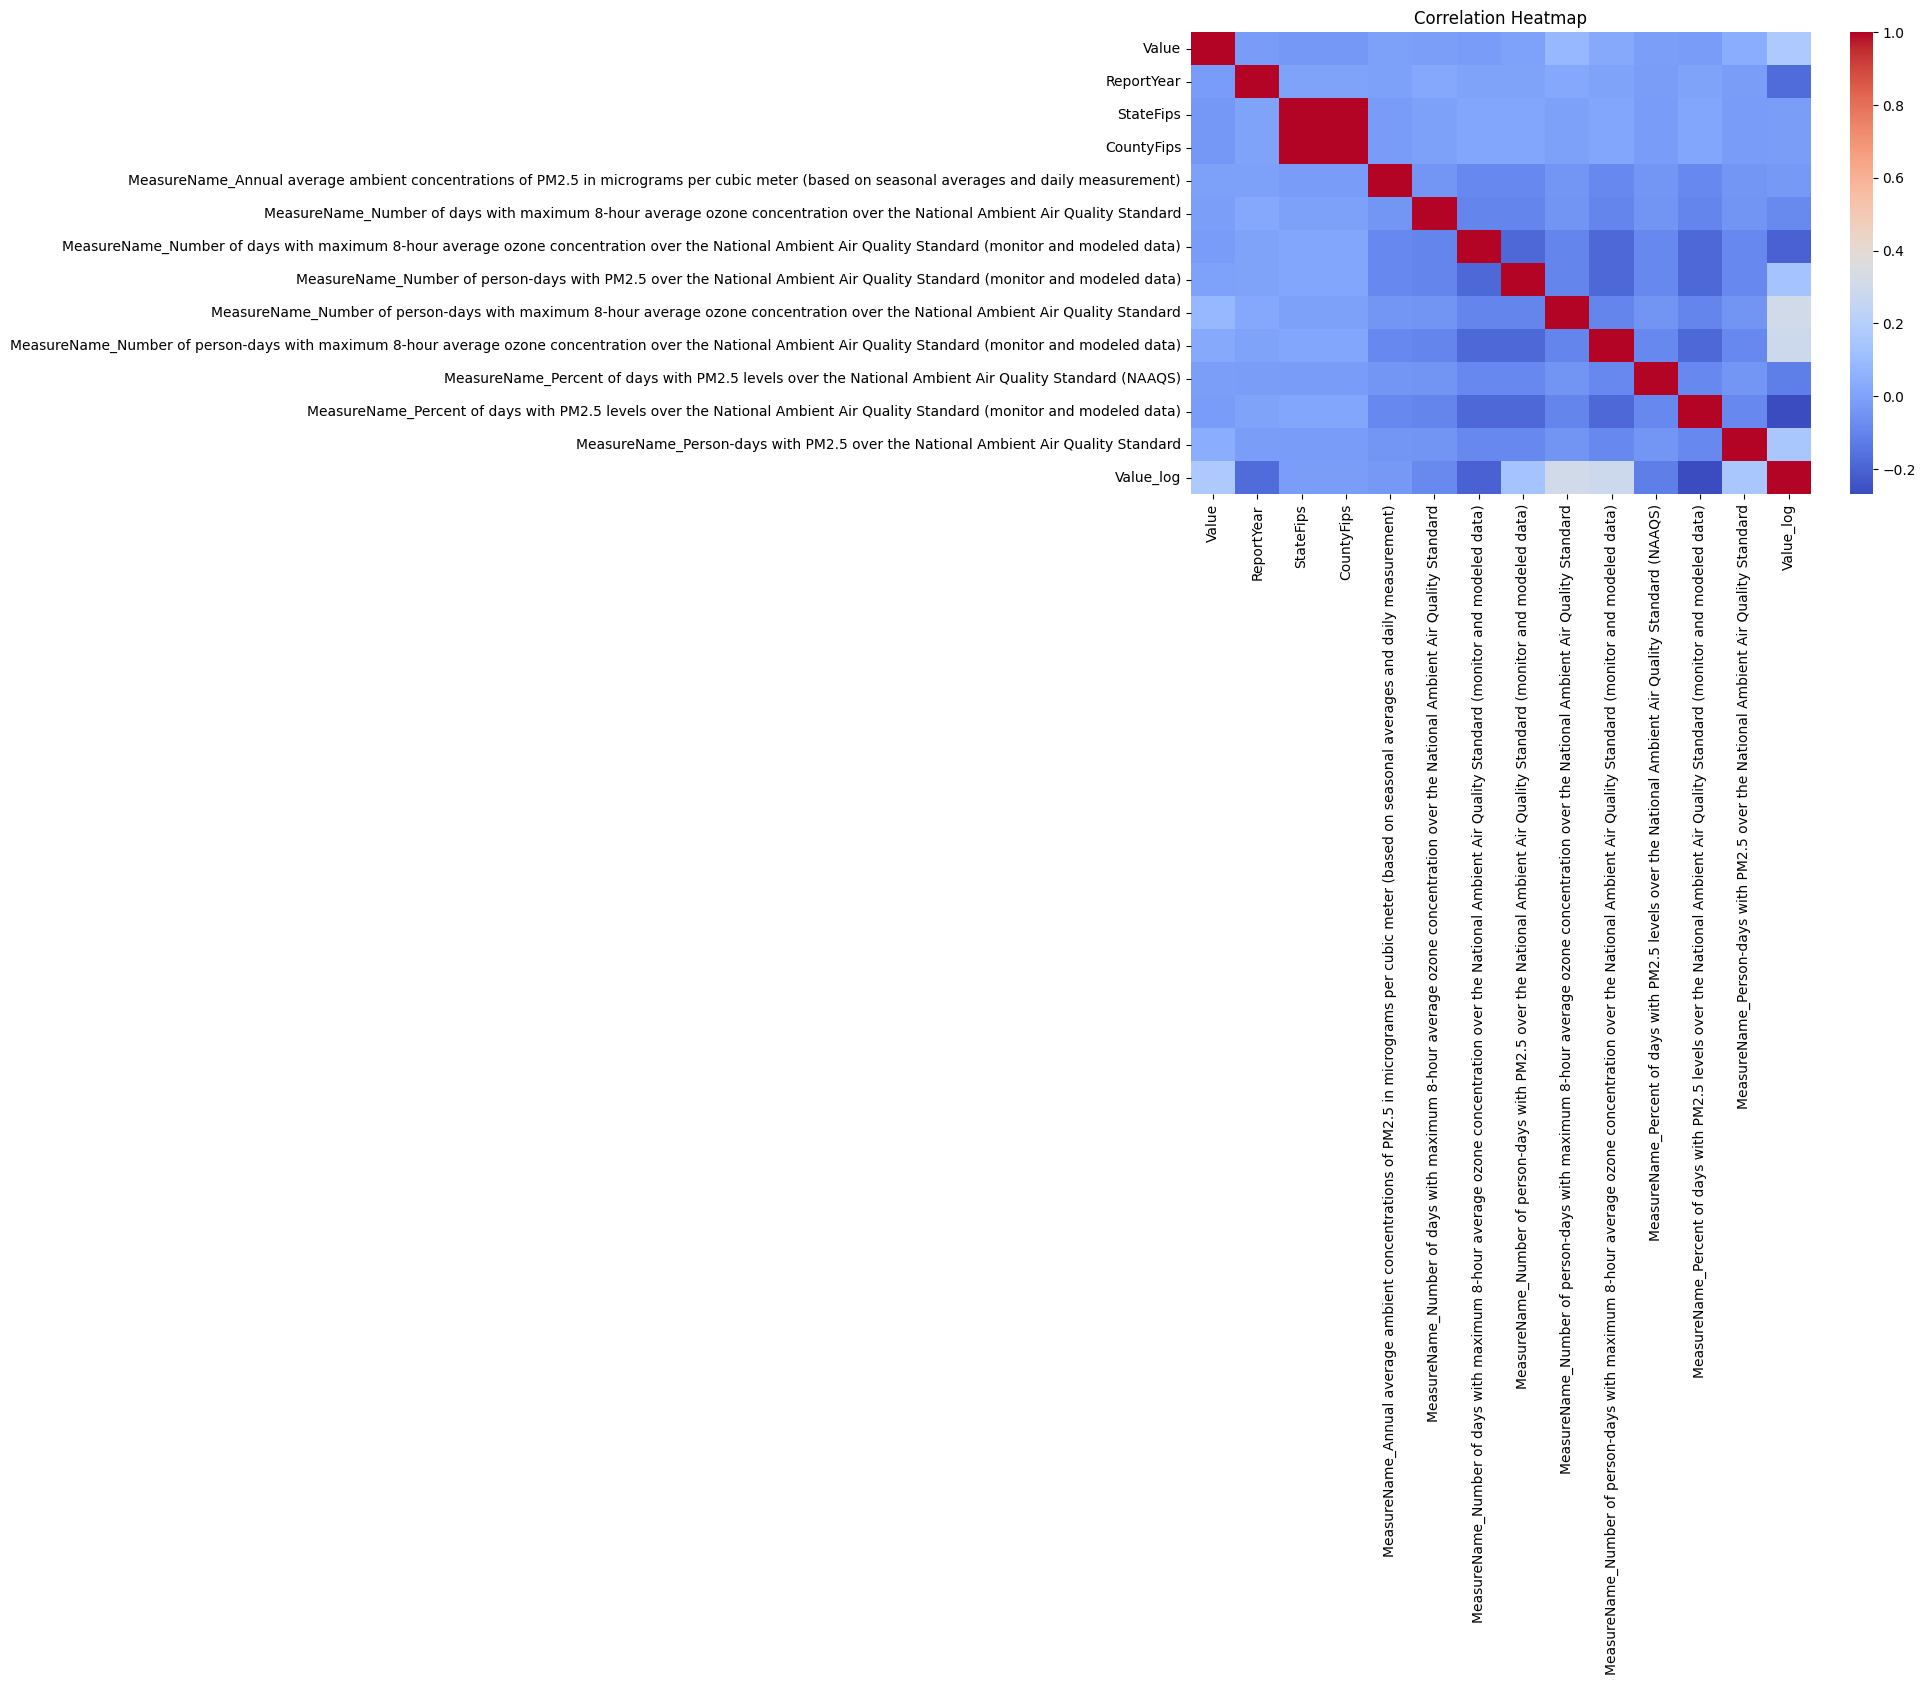

In [18]:
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()


## 4. Model: linear regression with a baseline

In [19]:
# ==============================
# Step 4.1: Define X and y
# ==============================

X = df.drop(['Value', 'Value_log'], axis=1)
y = df['Value_log']


In [20]:
# ==============================
# Step 4.2: Train-test split
# ==============================

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


In [21]:
# ==============================
# Step 4.3: Feature scaling
# ==============================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [22]:
# ==============================
# Step 4.4: Model training
# ==============================

lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)


LinearRegression()

In [23]:
# ==============================
# Step 4.5: Evaluation
# ==============================

y_pred = lr_model.predict(X_test_scaled)

print("Mean Absolute Error (MAE):", mean_absolute_error(y_test, y_pred))
print("Mean Squared Error (MSE):", mean_squared_error(y_test, y_pred))
print("R-squared (R²):", r2_score(y_test, y_pred))


Mean Absolute Error (MAE): 2.7770726060406488
Mean Squared Error (MSE): 15.299257568322815
R-squared (R²): 0.34902976890590887


In [24]:
# ==============================
# Step 4.6: Baseline model (always predicts the training mean)
# ==============================

baseline_pred = np.full_like(y_test, y_train.mean())

print("Baseline MAE:", mean_absolute_error(y_test, baseline_pred))
print("Baseline R²:", r2_score(y_test, baseline_pred))


Baseline MAE: 3.756421732912094
Baseline R²: -4.598847934267347e-05


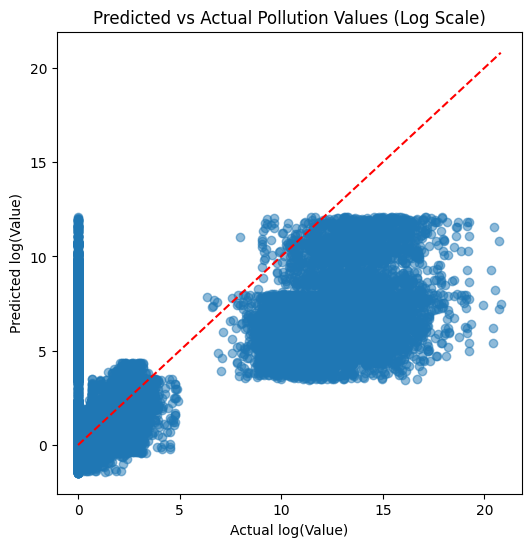

In [25]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual log(Value)")
plt.ylabel("Predicted log(Value)")
plt.title("Predicted vs Actual Pollution Values (Log Scale)")
plt.show()


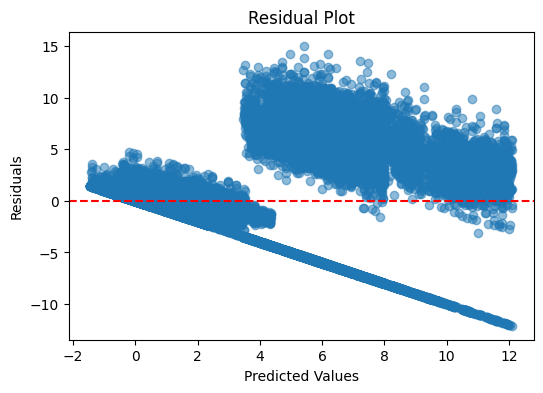

In [26]:
residuals = y_test - y_pred

plt.figure(figsize=(6,4))
plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


## 5. Explainability (SHAP)

In [27]:
# ==============================
# SHAP explainability
# ==============================

# SHAP explains how each feature contributes to predictions
explainer = shap.Explainer(lr_model, X_train_scaled)
shap_values = explainer(X_test_scaled)


/usr/local/lib/python3.13/dist-packages/shap/plots/_beeswarm.py:1151: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


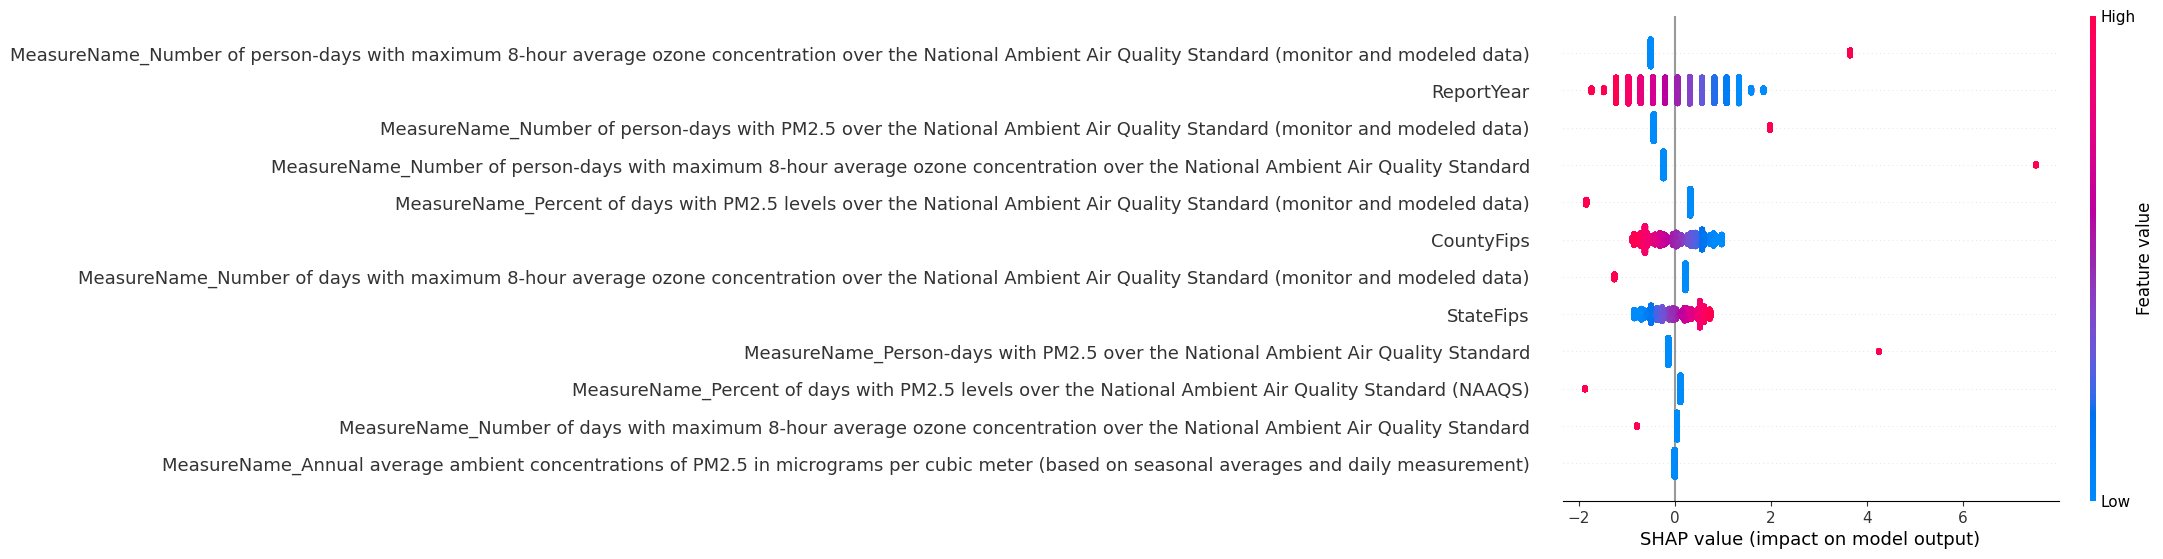

In [28]:
# Global feature importance
shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns
)


## 6. Findings and limitations

**Result:** the model explains about 35% of the variation in log pollution values (R² of about 0.35, MAE about 2.78) against a mean-only baseline (R² about 0.00, MAE about 3.76), so the selected features carry real signal.

**Limitations, and what I would do differently**
- **Mixed units in the target.** `Value` combines different measures with different units. A better approach is to model one measure at a time, or to standardise values within each measure before combining them.
- **Location codes used as numbers.** `StateFips` and `CountyFips` are codes, so treating them as numeric implies an order that does not exist. They should be one-hot encoded, grouped by region, or replaced with meaningful regional features.
- **Missing drivers.** Weather, traffic and industrial activity are not in the dataset, which limits how much variation any model can explain.
- **Pipeline next step.** For production use, the cleaning steps would move out of the notebook into a repeatable script with automated data quality checks, loading clean data into a database.